<a href="https://colab.research.google.com/github/GowreeshRaja/Spam-Classification-ML-vs-DistilBERT/blob/main/Spam_Classification_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparative Study of Traditional Machine Learning and Transformer Models for Spam Classification

**Objective:** To classify emails into Spam and Ham categories using traditional machine learning algorithms and a transformer-based DistilBERT model.

**Models:**
1. TF-IDF + Logistic Regression
2. TF-IDF + Multinomial Naive Bayes
3. DistilBERT using PyTorch

**Evaluation Metrics:** Accuracy, Precision, Recall, F1-score, Confusion Matrix, Training Time.

In [1]:

!pip install -q pandas numpy matplotlib seaborn scikit-learn transformers torch kagglehub


In [2]:

import os
import re
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Libraries imported successfully!
PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [3]:
from google.colab import files

uploaded = files.upload()

Saving email.csv to email.csv


In [4]:

import io

filename = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

df = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    encoding_errors="replace"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())
print("Column names:", df.columns.tolist())


Dataset loaded successfully!
Dataset shape: (5573, 2)


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Column names: ['Category', 'Message']


In [5]:

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Remove rows with missing category or message
df = df.dropna(subset=["Category", "Message"])

# Remove duplicate rows
df = df.drop_duplicates()

# Remove leading and trailing spaces
df["Category"] = df["Category"].str.strip().str.lower()
df["Message"] = df["Message"].astype(str).str.strip()

# Keep only valid labels
df = df[df["Category"].isin(["ham", "spam"])]

# Remove empty messages
df = df[df["Message"] != ""]

# Reset row numbering
df = df.reset_index(drop=True)

print("\nDataset after cleaning:")
print("Shape:", df.shape)

print("\nCategory counts:")
print(df["Category"].value_counts())

display(df.head())


Missing values before cleaning:
Category    0
Message     0
dtype: int64

Number of duplicate rows:
415

Dataset after cleaning:
Shape: (5157, 2)

Category counts:
Category
ham     4516
spam     641
Name: count, dtype: int64


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


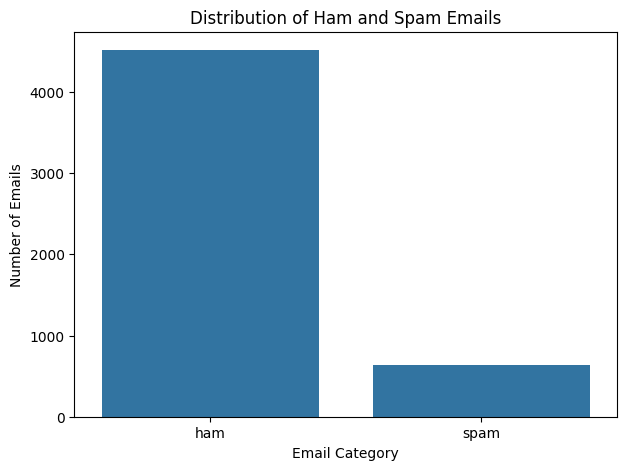

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Category"
)

plt.title("Distribution of Ham and Spam Emails")
plt.xlabel("Email Category")
plt.ylabel("Number of Emails")

plt.show()


In [7]:

category_counts = df["Category"].value_counts()

category_percentages = (
    df["Category"].value_counts(normalize=True) * 100
)

print("Email counts:")
print(category_counts)

print("\nEmail percentages:")
print(category_percentages.round(2))

print("\nTotal emails:", len(df))


Email counts:
Category
ham     4516
spam     641
Name: count, dtype: int64

Email percentages:
Category
ham     87.57
spam    12.43
Name: proportion, dtype: float64

Total emails: 5157


In [8]:

# Convert text labels into numeric labels

df["label"] = df["Category"].map({
    "ham": 0,
    "spam": 1
})

# Separate input messages and target labels
X = df["Message"]
y = df["label"]

print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

print("\nLabel mapping:")
print("Ham = 0")
print("Spam = 1")

print("\nLabel counts:")
print(y.value_counts())



Input data shape: (5157,)
Target data shape: (5157,)

Label mapping:
Ham = 0
Spam = 1

Label counts:
label
0    4516
1     641
Name: count, dtype: int64


In [9]:

from sklearn.model_selection import train_test_split

# First: 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split temporary data equally into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nSpam distribution in each split:")
print("Training:")
print(y_train.value_counts())

print("\nValidation:")
print(y_val.value_counts())

print("\nTesting:")
print(y_test.value_counts())


Training samples: 3609
Validation samples: 774
Testing samples: 774

Spam distribution in each split:
Training:
label
0    3160
1     449
Name: count, dtype: int64

Validation:
label
0    678
1     96
Name: count, dtype: int64

Testing:
label
0    678
1     96
Name: count, dtype: int64


In [10]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import time

# Create the model pipeline
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
start_time = time.time()

lr_model.fit(X_train, y_train)

lr_training_time = time.time() - start_time

# Evaluate on the validation set
lr_val_pred = lr_model.predict(X_val)

print("Logistic Regression Results")
print("---------------------------")
print("Training time:", round(lr_training_time, 2), "seconds")

print(
    "Accuracy:",
    round(accuracy_score(y_val, lr_val_pred), 4)
)

print(
    "Spam Precision:",
    round(precision_score(y_val, lr_val_pred, zero_division=0), 4)
)

print(
    "Spam Recall:",
    round(recall_score(y_val, lr_val_pred, zero_division=0), 4)
)

print(
    "Spam F1-score:",
    round(f1_score(y_val, lr_val_pred, zero_division=0), 4)
)

print("\nClassification Report:")
print(classification_report(
    y_val,
    lr_val_pred,
    target_names=["Ham", "Spam"],
    zero_division=0
))


Logistic Regression Results
---------------------------
Training time: 1.15 seconds
Accuracy: 0.9587
Spam Precision: 1.0
Spam Recall: 0.6667
Spam F1-score: 0.8

Classification Report:
              precision    recall  f1-score   support

         Ham       0.95      1.00      0.98       678
        Spam       1.00      0.67      0.80        96

    accuracy                           0.96       774
   macro avg       0.98      0.83      0.89       774
weighted avg       0.96      0.96      0.95       774



In [11]:

# Create the Naive Bayes pipeline

nb_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", MultinomialNB(alpha=0.5))
])

# Train the model
start_time = time.time()

nb_model.fit(X_train, y_train)

nb_training_time = time.time() - start_time

# Predict validation labels
nb_val_pred = nb_model.predict(X_val)

# Display results
print("Naive Bayes Results")
print("-------------------")
print("Training time:", round(nb_training_time, 2), "seconds")

print(
    "Accuracy:",
    round(accuracy_score(y_val, nb_val_pred), 4)
)

print(
    "Spam Precision:",
    round(precision_score(y_val, nb_val_pred, zero_division=0), 4)
)

print(
    "Spam Recall:",
    round(recall_score(y_val, nb_val_pred, zero_division=0), 4)
)

print(
    "Spam F1-score:",
    round(f1_score(y_val, nb_val_pred, zero_division=0), 4)
)

print("\nClassification Report:")
print(classification_report(
    y_val,
    nb_val_pred,
    target_names=["Ham", "Spam"],
    zero_division=0
))


Naive Bayes Results
-------------------
Training time: 0.36 seconds
Accuracy: 0.9677
Spam Precision: 1.0
Spam Recall: 0.7396
Spam F1-score: 0.8503

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       678
        Spam       1.00      0.74      0.85        96

    accuracy                           0.97       774
   macro avg       0.98      0.87      0.92       774
weighted avg       0.97      0.97      0.97       774



In [12]:

# Store validation results for comparison

comparison_data = [
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_val, lr_val_pred),
        "Precision": precision_score(
            y_val, lr_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, lr_val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, lr_val_pred, zero_division=0
        ),
        "Training Time (seconds)": lr_training_time
    },
    {
        "Model": "Naive Bayes",
        "Accuracy": accuracy_score(y_val, nb_val_pred),
        "Precision": precision_score(
            y_val, nb_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, nb_val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, nb_val_pred, zero_division=0
        ),
        "Training Time (seconds)": nb_training_time
    }
]

comparison_df = pd.DataFrame(comparison_data)

display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1-score,Training Time (seconds)
0,Logistic Regression,0.9587,1.0,0.6667,0.8000,1.1548
1,Naive Bayes,0.9677,1.0,0.7396,0.8503,0.3583


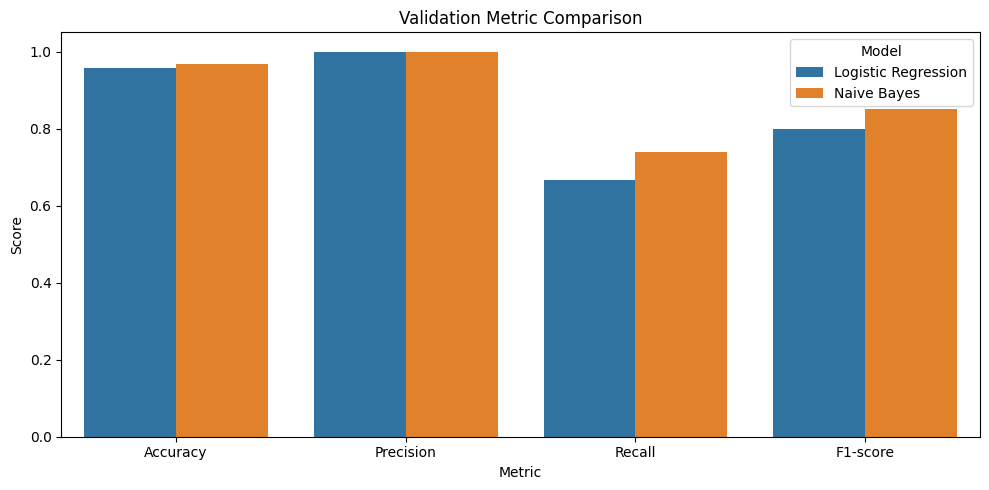

In [13]:

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

comparison_long = comparison_df.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Validation Metric Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()


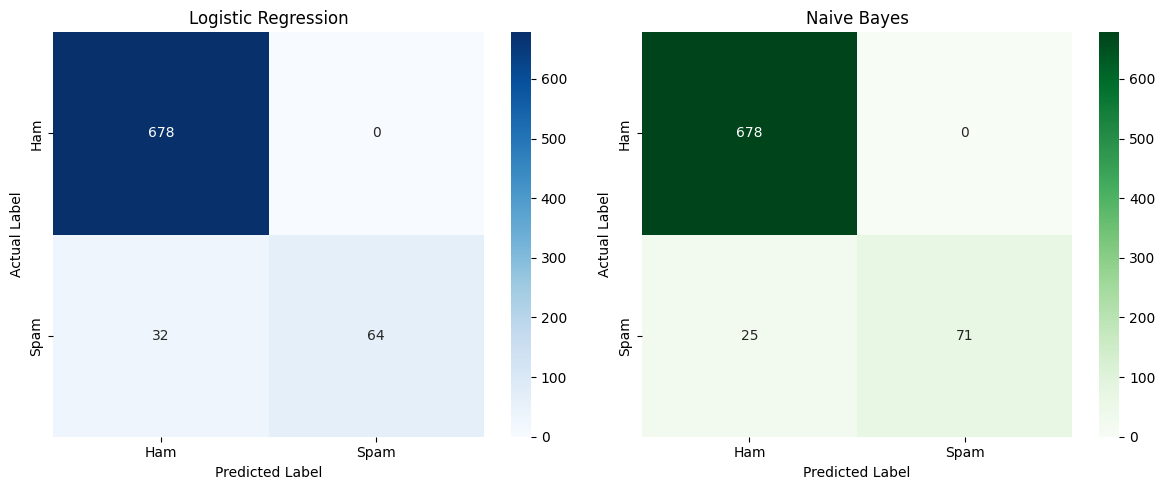

In [14]:

# Predictions on the validation set
lr_cm = confusion_matrix(
    y_val, lr_val_pred, labels=[0, 1]
)

nb_cm = confusion_matrix(
    y_val, nb_val_pred, labels=[0, 1]
)

# Plot both confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"],
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(
    nb_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"],
    ax=axes[1]
)

axes[1].set_title("Naive Bayes")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


In [15]:

# Predict on the held-out test set
lr_test_pred = lr_model.predict(X_test)
nb_test_pred = nb_model.predict(X_test)

# Calculate final test metrics
test_results = []

for name, predictions in [
    ("Logistic Regression", lr_test_pred),
    ("Naive Bayes", nb_test_pred)
]:
    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Spam Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Spam Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Spam F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

print("\nLogistic Regression Test Report:")
print(classification_report(
    y_test,
    lr_test_pred,
    target_names=["Ham", "Spam"],
    zero_division=0
))

print("\nNaive Bayes Test Report:")
print(classification_report(
    y_test,
    nb_test_pred,
    target_names=["Ham", "Spam"],
    zero_division=0
))


,Model,Accuracy,Spam Precision,Spam Recall,Spam F1-score
0,Logistic Regression,0.9651,1.0,0.7188,0.8364
1,Naive Bayes,0.9780,1.0,0.8229,0.9029



Logistic Regression Test Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       678
        Spam       1.00      0.72      0.84        96

    accuracy                           0.97       774
   macro avg       0.98      0.86      0.91       774
weighted avg       0.97      0.97      0.96       774


Naive Bayes Test Report:
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       678
        Spam       1.00      0.82      0.90        96

    accuracy                           0.98       774
   macro avg       0.99      0.91      0.95       774
weighted avg       0.98      0.98      0.98       774



In [16]:

!pip install -q transformers


In [17]:

import torch
import time
import numpy as np

from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    DistilBertForSequenceClassification,
    get_linear_schedule_with_warmup
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Warning: CPU detected. DistilBERT training may be slow.")


Using device: cuda
GPU: Tesla T4


In [18]:

from transformers import AutoTokenizer

model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("DistilBERT tokenizer loaded successfully!")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

DistilBERT tokenizer loaded successfully!


In [19]:

sample_text = "Congratulations! You won a free prize."

encoded = tokenizer(
    sample_text,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print("Original text:", sample_text)

print("\nInput IDs:")
print(encoded["input_ids"])

print("\nAttention Mask:")
print(encoded["attention_mask"])


Original text: Congratulations! You won a free prize.

Input IDs:
tensor([[  101, 23156,   999,  2017,  2180,  1037,  2489,  3396,  1012,   102,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0, 

In [20]:

from torch.utils.data import Dataset, DataLoader

class SpamDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        text = str(self.texts[index])
        label = int(self.labels[index])

        encoding = self.tokenizer(
            text,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(label, dtype=torch.long)
        }

print("Custom PyTorch Dataset created successfully!")


Custom PyTorch Dataset created successfully!


In [21]:

# Create datasets
train_dataset = SpamDataset(
    X_train, y_train, tokenizer
)

val_dataset = SpamDataset(
    X_val, y_val, tokenizer
)

test_dataset = SpamDataset(
    X_test, y_test, tokenizer
)

# Set batch size
batch_size = 16

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


DataLoaders created successfully!
Training batches: 226
Validation batches: 49
Testing batches: 49


In [22]:

from transformers import DistilBertForSequenceClassification

model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

model = model.to(device)

print("DistilBERT model loaded successfully!")
print("Model running on:", device)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully!
Model running on: cuda


In [23]:

from transformers import get_linear_schedule_with_warmup

# Training hyperparameters
learning_rate = 2e-5
epochs = 3
weight_decay = 0.01

# AdamW optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)

# Learning rate scheduler
total_steps = len(train_loader) * epochs

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

print("Training configuration ready!")
print("Learning rate:", learning_rate)
print("Epochs:", epochs)
print("Batch size:", batch_size)
print("Weight decay:", weight_decay)
print("Total training steps:", total_steps)


Training configuration ready!
Learning rate: 2e-05
Epochs: 3
Batch size: 16
Weight decay: 0.01
Total training steps: 678


In [24]:

# Function to evaluate DistilBERT

def evaluate_model(model, data_loader):

    model.eval()

    total_loss = 0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for batch in data_loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss
            logits = outputs.logits

            total_loss += loss.item()

            predictions = torch.argmax(logits, dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    avg_loss = total_loss / len(data_loader)

    accuracy = accuracy_score(
        all_labels, all_predictions
    )

    precision = precision_score(
        all_labels, all_predictions,
        zero_division=0
    )

    recall = recall_score(
        all_labels, all_predictions,
        zero_division=0
    )

    f1 = f1_score(
        all_labels, all_predictions,
        zero_division=0
    )

    return avg_loss, accuracy, precision, recall, f1


print("Evaluation function created successfully!")


Evaluation function created successfully!


In [25]:

# Custom PyTorch training loop

train_losses = []
val_losses = []
val_accuracies = []
val_precisions = []
val_recalls = []
val_f1_scores = []

best_val_f1 = -1.0
best_epoch = 0

training_start_time = time.time()

for epoch in range(epochs):

    print(f"\nEpoch {epoch + 1}/{epochs}")
    print("-" * 40)

    model.train()

    total_train_loss = 0

    for batch in train_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        # Backpropagation
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        # Update model weights
        optimizer.step()

        # Update learning rate
        scheduler.step()

        total_train_loss += loss.item()

    # Average training loss
    avg_train_loss = total_train_loss / len(train_loader)

    # Evaluate on validation data
    val_loss, val_acc, val_prec, val_rec, val_f1 = (
        evaluate_model(model, val_loader)
    )

    # Store results
    train_losses.append(avg_train_loss)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)
    val_precisions.append(val_prec)
    val_recalls.append(val_rec)
    val_f1_scores.append(val_f1)

    print(f"Training Loss: {avg_train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Validation Precision: {val_prec:.4f}")
    print(f"Validation Recall: {val_rec:.4f}")
    print(f"Validation F1-score: {val_f1:.4f}")

    # Save best model using validation F1
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch + 1

        model.save_pretrained(
            "/content/best_distilbert_spam"
        )

        tokenizer.save_pretrained(
            "/content/best_distilbert_spam"
        )

        print("Best model saved!")

# Total training time
distilbert_training_time = (
    time.time() - training_start_time
)

print("\nTraining completed successfully!")
print("Best epoch:", best_epoch)
print("Best validation F1:", round(best_val_f1, 4))

print(
    "Total training time:",
    round(distilbert_training_time, 2),
    "seconds"
)



Epoch 1/3
----------------------------------------
Training Loss: 0.1609
Validation Loss: 0.0604
Validation Accuracy: 0.9845
Validation Precision: 0.9667
Validation Recall: 0.9062
Validation F1-score: 0.9355


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved!

Epoch 2/3
----------------------------------------
Training Loss: 0.0242
Validation Loss: 0.0652
Validation Accuracy: 0.9858
Validation Precision: 0.9885
Validation Recall: 0.8958
Validation F1-score: 0.9399


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved!

Epoch 3/3
----------------------------------------
Training Loss: 0.0123
Validation Loss: 0.0745
Validation Accuracy: 0.9871
Validation Precision: 1.0000
Validation Recall: 0.8958
Validation F1-score: 0.9451


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved!

Training completed successfully!
Best epoch: 3
Best validation F1: 0.9451
Total training time: 133.39 seconds


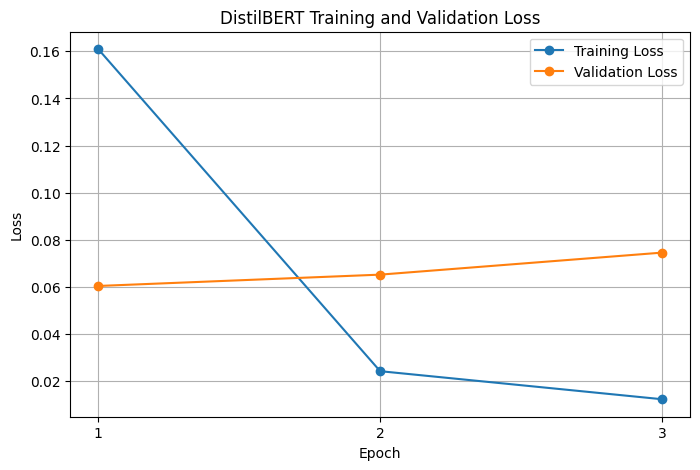

In [26]:

# Plot training and validation loss

epoch_numbers = range(1, epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epoch_numbers,
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.title("DistilBERT Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epoch_numbers))
plt.legend()
plt.grid(True)

plt.show()


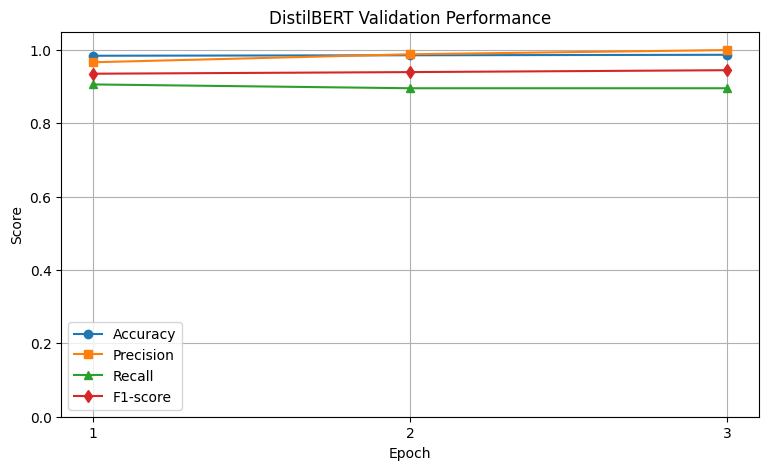

In [27]:

# Plot validation metrics

plt.figure(figsize=(9, 5))

plt.plot(
    epoch_numbers,
    val_accuracies,
    marker="o",
    label="Accuracy"
)

plt.plot(
    epoch_numbers,
    val_precisions,
    marker="s",
    label="Precision"
)

plt.plot(
    epoch_numbers,
    val_recalls,
    marker="^",
    label="Recall"
)

plt.plot(
    epoch_numbers,
    val_f1_scores,
    marker="d",
    label="F1-score"
)

plt.title("DistilBERT Validation Performance")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.xticks(list(epoch_numbers))
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)

plt.show()


In [28]:

# Load best saved DistilBERT model

from transformers import DistilBertForSequenceClassification

best_model = DistilBertForSequenceClassification.from_pretrained(
    "/content/best_distilbert_spam"
)

best_model = best_model.to(device)
best_model.eval()

print("Best DistilBERT model loaded successfully!")
print("Best epoch:", best_epoch)
print("Best validation F1-score:", round(best_val_f1, 4))


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Best DistilBERT model loaded successfully!
Best epoch: 3
Best validation F1-score: 0.9451


In [29]:

# Evaluate DistilBERT on the test set

all_predictions = []
all_labels = []

test_start_time = time.time()

best_model.eval()

with torch.no_grad():

    for batch in test_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = best_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(
            outputs.logits, dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy().tolist()
        )

        all_labels.extend(
            labels.cpu().numpy().tolist()
        )

distilbert_test_time = time.time() - test_start_time

distilbert_accuracy = accuracy_score(
    all_labels, all_predictions
)

distilbert_precision = precision_score(
    all_labels, all_predictions,
    zero_division=0
)

distilbert_recall = recall_score(
    all_labels, all_predictions,
    zero_division=0
)

distilbert_f1 = f1_score(
    all_labels, all_predictions,
    zero_division=0
)

print("DistilBERT Test Results")
print("----------------------")

print("Accuracy:", round(distilbert_accuracy, 4))
print("Precision:", round(distilbert_precision, 4))
print("Recall:", round(distilbert_recall, 4))
print("F1-score:", round(distilbert_f1, 4))

print(
    "Test inference time:",
    round(distilbert_test_time, 2),
    "seconds"
)

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Ham", "Spam"],
    zero_division=0
))


DistilBERT Test Results
----------------------
Accuracy: 0.9884
Precision: 0.978
Recall: 0.9271
F1-score: 0.9519
Test inference time: 3.31 seconds

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       678
        Spam       0.98      0.93      0.95        96

    accuracy                           0.99       774
   macro avg       0.98      0.96      0.97       774
weighted avg       0.99      0.99      0.99       774



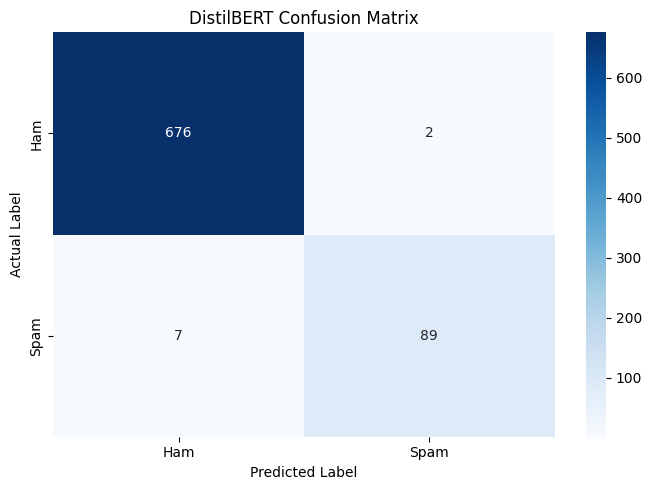

In [30]:

# DistilBERT confusion matrix

distilbert_cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    distilbert_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("DistilBERT Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()


In [31]:

# Final comparison of all three models

final_results = [
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, lr_test_pred),
        "Precision": precision_score(
            y_test, lr_test_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, lr_test_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, lr_test_pred, zero_division=0
        )
    },
    {
        "Model": "Naive Bayes",
        "Accuracy": accuracy_score(y_test, nb_test_pred),
        "Precision": precision_score(
            y_test, nb_test_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, nb_test_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, nb_test_pred, zero_division=0
        )
    },
    {
        "Model": "DistilBERT",
        "Accuracy": distilbert_accuracy,
        "Precision": distilbert_precision,
        "Recall": distilbert_recall,
        "F1-score": distilbert_f1
    }
]

final_df = pd.DataFrame(final_results)

print("Final Model Comparison - Test Set")
display(final_df.round(4))


Final Model Comparison - Test Set


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9651,1.000,0.7188,0.8364
1,Naive Bayes,0.9780,1.000,0.8229,0.9029
2,DistilBERT,0.9884,0.978,0.9271,0.9519


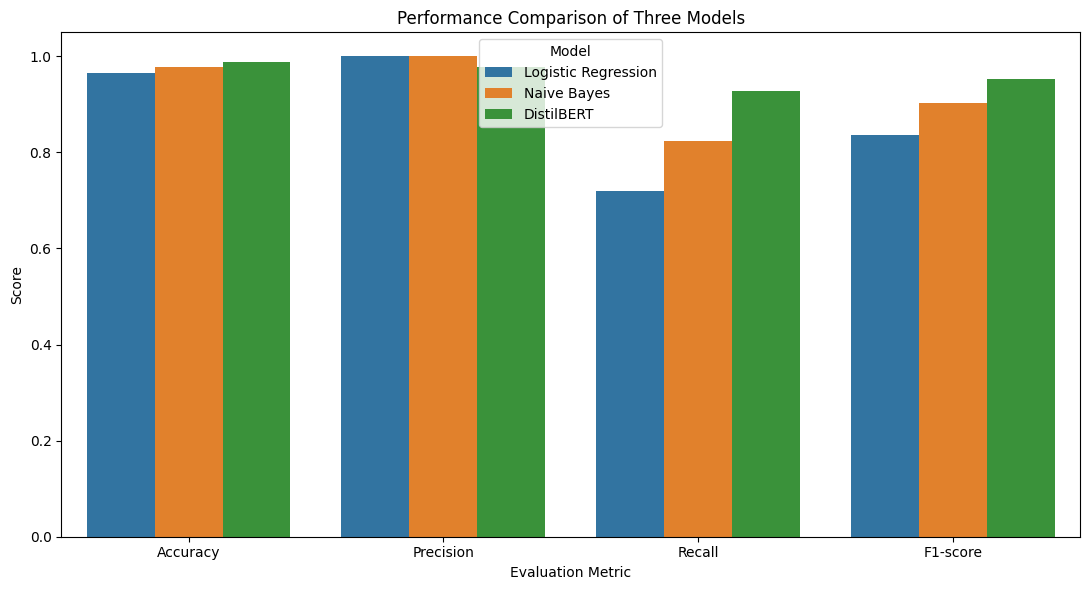

In [32]:

# Compare accuracy, precision, recall and F1

final_long = final_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=final_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Performance Comparison of Three Models")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


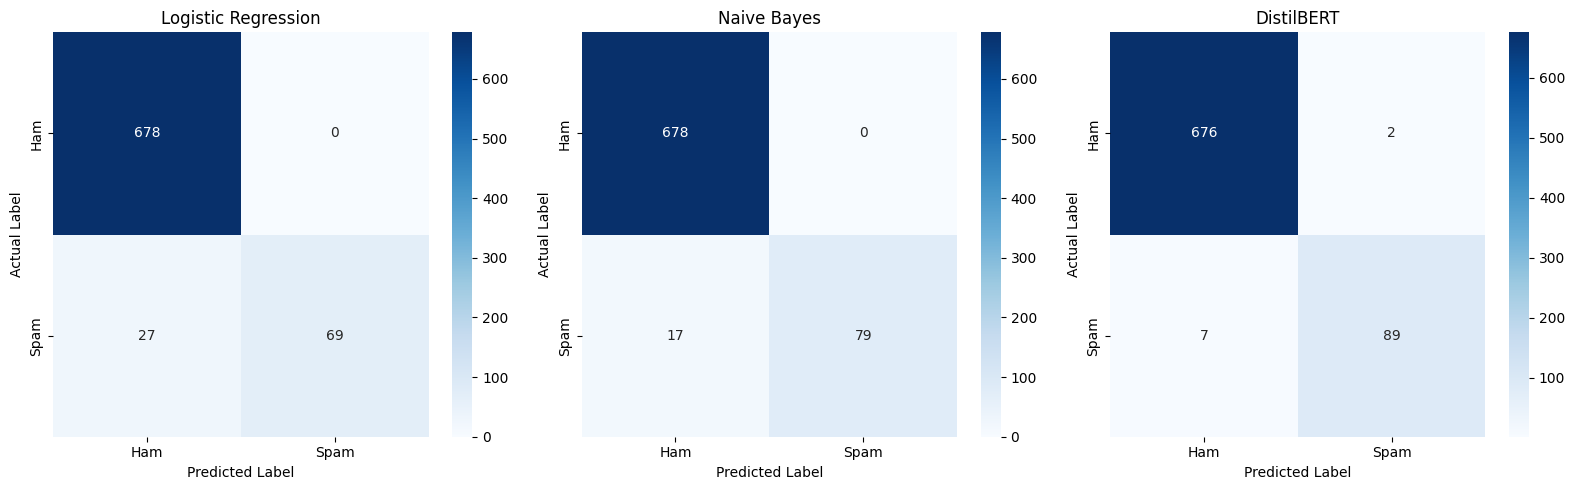

In [33]:

# Final test confusion matrices

predictions_dict = {
    "Logistic Regression": lr_test_pred,
    "Naive Bayes": nb_test_pred,
    "DistilBERT": all_predictions
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, predictions) in zip(
    axes, predictions_dict.items()
):
    cm = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    "all_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


,Model,Training Time (seconds)
0,Logistic Regression,1.15
1,Naive Bayes,0.36
2,DistilBERT,133.39


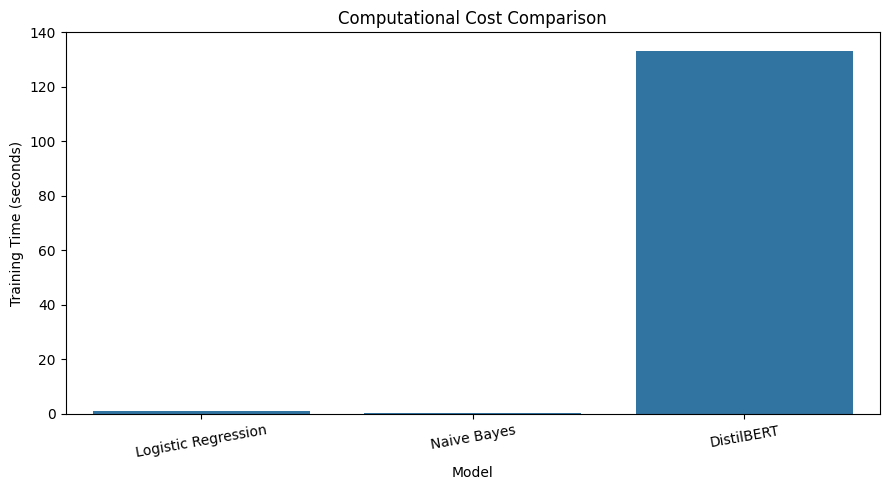

In [34]:

# Training time comparison

training_times = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "DistilBERT"
    ],
    "Training Time (seconds)": [
        lr_training_time,
        nb_training_time,
        distilbert_training_time
    ]
})

display(training_times.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=training_times,
    x="Model",
    y="Training Time (seconds)"
)

plt.title("Computational Cost Comparison")
plt.xlabel("Model")
plt.ylabel("Training Time (seconds)")
plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig(
    "training_time_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [35]:

# Save results to CSV files

final_df.to_csv(
    "final_model_results.csv",
    index=False
)

training_times.to_csv(
    "training_times.csv",
    index=False
)

training_history = pd.DataFrame({
    "Epoch": list(range(1, len(train_losses) + 1)),
    "Training Loss": train_losses,
    "Validation Loss": val_losses,
    "Validation Accuracy": val_accuracies,
    "Validation Precision": val_precisions,
    "Validation Recall": val_recalls,
    "Validation F1": val_f1_scores
})

training_history.to_csv(
    "distilbert_training_history.csv",
    index=False
)

print("All results saved successfully!")


All results saved successfully!


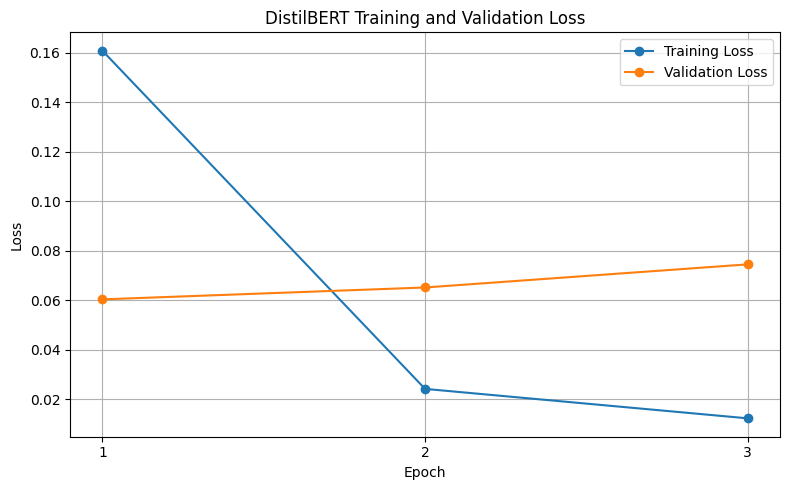

In [36]:

# Save DistilBERT training loss plot

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, epochs + 1),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DistilBERT Training and Validation Loss")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "distilbert_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


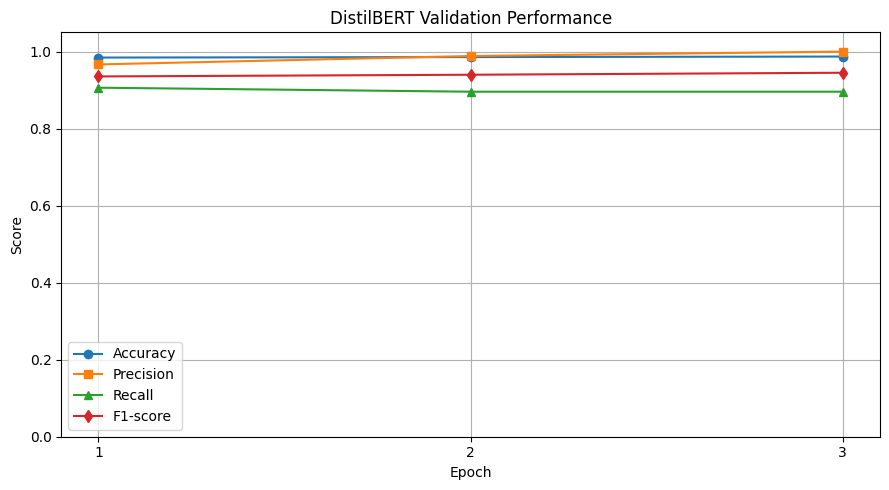

In [37]:

# Save DistilBERT validation performance

plt.figure(figsize=(9, 5))

plt.plot(val_accuracies, marker="o", label="Accuracy")
plt.plot(val_precisions, marker="s", label="Precision")
plt.plot(val_recalls, marker="^", label="Recall")
plt.plot(val_f1_scores, marker="d", label="F1-score")

plt.xticks(
    range(epochs),
    range(1, epochs + 1)
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("DistilBERT Validation Performance")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "distilbert_validation_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [38]:

import os
import zipfile
from google.colab import files

output_files = [
    "model_comparison.png",
    "all_confusion_matrices.png",
    "training_time_comparison.png",
    "distilbert_loss.png",
    "distilbert_validation_metrics.png",
    "final_model_results.csv",
    "training_times.csv",
    "distilbert_training_history.csv"
]

with zipfile.ZipFile(
    "Spam_Classification_Results.zip", "w"
) as zipf:

    for filename in output_files:
        if os.path.exists(filename):
            zipf.write(filename)
        else:
            print("Missing file:", filename)

print("Results ZIP created successfully!")

files.download("Spam_Classification_Results.zip")


Results ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>